#### **Safety Stock, Reorder Point (ROP) & Procurement Escalation Engine**

- This notebook runs the replenishment optimization engine on the UAE fleet inventory snapshot to determine:
    * Safety Stock ($SS$): $Z \times \sigma_d \times \sqrt{\text{Lead Time in Months}}$, driven by criticality service levels (99% for High, 95% for Medium, 90% for Low).
    * Reorder Point ($ROP$): $(\text{Average Monthly Demand} \times \text{Lead Time in Months}) + SS$.
    * Target Stock Level: $ROP + (\text{Average Monthly Demand} \times \text{Review Cycle Months})$.
    * Recommended Order Quantity: $\max(0, \text{Target Stock Level} - \text{Net Available Stock})$ when $\text{Net Available Stock} \le ROP$.
    * Action Classification & Urgent PR Escalations: Prioritizes immediate orders, stock-out risks, excess stock in AED, and delayed vehicle work orders.

#### **Environment Setup & Replenishment Calculation**

In [1]:
import sys
from pathlib import Path
import pandas as pd
import plotly.express as px

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.inventory_metrics import compute_stock_positions, classify_abc_xyz
from src.replenishment_engine import compute_replenishment_plan

raw_dir = PROJECT_ROOT / "data" / "raw"
proc_dir = PROJECT_ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

inv_df = pd.read_csv(raw_dir / "inventory_snapshot.csv")
po_df = pd.read_csv(raw_dir / "open_purchase_orders.csv")
bo_df = pd.read_csv(raw_dir / "backordered_work_orders.csv")

metrics_df = classify_abc_xyz(compute_stock_positions(inv_df, po_df))
plan_df = compute_replenishment_plan(metrics_df, backorder_wo_df=bo_df)

print(f"Replenishment plan generated for {len(plan_df)} SKUs.")
print("\n== Action Distribution ==")
print(plan_df["recommended_action"].value_counts())

Replenishment plan generated for 28 SKUs.

== Action Distribution ==
recommended_action
Reorder now        16
Excess stock        6
Monitor closely     3
Healthy             3
Name: count, dtype: int64


#### **Safety Stock, ROP & Target Stock Schedule**

In [2]:
rop_cols = [
    "part_number",
    "part_name",
    "criticality",
    "target_service_level_pct",
    "z_score",
    "avg_monthly_demand",
    "lead_time_days",
    "safety_stock_qty",
    "reorder_point_qty",
    "target_stock_qty",
    "net_available_stock",
    "recommended_order_qty",
    "recommended_order_value_aed",
    "recommended_action",
]
display(plan_df[rop_cols].head(5))

,part_number,part_name,criticality,target_service_level_pct,z_score,avg_monthly_demand,lead_time_days,safety_stock_qty,reorder_point_qty,target_stock_qty,net_available_stock,recommended_order_qty,recommended_order_value_aed,recommended_action
0,PRT-013,24V Heavy-Duty AGM Battery,High,99.0,2.33,24.0,14,10,22,46,5,41,36490.0,Reorder now
1,PRT-005,Front Disc Brake Pad Set,High,99.0,2.33,30.0,21,15,36,66,14,52,24960.0,Reorder now
2,PRT-009,A/C Compressor Assembly (Heavy),High,99.0,2.33,8.5,35,15,25,34,0,34,62900.0,Reorder now
3,PRT-010,Radiator Core Assembly,High,99.0,2.33,5.5,40,12,20,26,4,22,48400.0,Reorder now
4,PRT-018,Drive Axle Radial Tyre (315/80R22.5),High,99.0,2.33,36.0,20,17,41,77,2,75,111000.0,Reorder now


#### **Urgent Purchase Requisition (PR) Escalations & Delayed Work Orders**

Urgent PR Escalations: 13 parts | Urgent PO Value: AED 450,340.00 | Delayed WOs: 15 | Downtime: 1,079.5 hrs


,part_number,part_name,hub_location,supplier,criticality,net_available_stock,reorder_point_qty,recommended_order_qty,recommended_order_value_aed,delayed_wo_count,total_wo_downtime_hrs,stockout_risk_score
0,PRT-013,24V Heavy-Duty AGM Battery,Jebel Ali Hub,Emirates Battery Corp,High,5,22,41,36490.0,3,187.0,100.0
1,PRT-005,Front Disc Brake Pad Set,Jebel Ali Hub,Arabian Brake & Axle Co.,High,14,36,52,24960.0,3,255.0,100.0
2,PRT-009,A/C Compressor Assembly (Heavy),Jebel Ali Hub,Denso Thermal UAE,High,0,25,34,62900.0,2,144.5,94.0
3,PRT-010,Radiator Core Assembly,Mussafah Hub,Denso Thermal UAE,High,4,20,22,48400.0,2,170.0,94.0
4,PRT-018,Drive Axle Radial Tyre (315/80R22.5),Mussafah Hub,Bridgestone MEA,High,2,41,75,111000.0,1,59.5,87.0
5,PRT-025,Turbocharger Actuator Valve,Jebel Ali Hub,Al-Futtaim Auto Parts UAE,High,1,14,16,39200.0,1,34.0,87.0
6,PRT-021,Clutch Pressure Plate & Disc Kit,Mussafah Hub,ZF Middle East,High,2,17,20,39000.0,1,68.0,87.0
7,PRT-007,ABS Wheel Speed Sensor,Jebel Ali Hub,Bosch Middle East FZE,High,4,21,28,8960.0,1,119.0,87.0
8,PRT-002,Primary Fuel Water Separator,Jebel Ali Hub,Emirates Fleet Supply,High,16,36,54,8910.0,1,42.5,87.0
9,PRT-015,Starter Motor Assembly,Sajaa Hub,Bosch Middle East FZE,High,6,18,19,24320.0,0,0.0,80.0



== Spare Parts Driving Delayed Vehicle Work Orders ==


,part_number,part_name,vehicle_type,hub_location,usable_on_hand_qty,safety_stock_qty,delayed_wo_count,total_wo_delay_days,total_wo_downtime_hrs,recommended_action
1,PRT-005,Front Disc Brake Pad Set,Heavy Truck,Jebel Ali Hub,0.0,15,3,30,255.0,Reorder now
0,PRT-013,24V Heavy-Duty AGM Battery,Heavy Truck,Jebel Ali Hub,6.0,10,3,22,187.0,Reorder now
3,PRT-010,Radiator Core Assembly,Coach / Bus,Mussafah Hub,4.0,12,2,20,170.0,Reorder now
2,PRT-009,A/C Compressor Assembly (Heavy),Heavy Truck,Jebel Ali Hub,1.0,15,2,17,144.5,Reorder now
7,PRT-007,ABS Wheel Speed Sensor,Coach / Bus,Jebel Ali Hub,4.0,11,1,14,119.0,Reorder now
6,PRT-021,Clutch Pressure Plate & Disc Kit,Medium Truck,Mussafah Hub,3.0,11,1,8,68.0,Reorder now
4,PRT-018,Drive Axle Radial Tyre (315/80R22.5),Heavy Truck,Mussafah Hub,3.0,17,1,7,59.5,Reorder now
8,PRT-002,Primary Fuel Water Separator,Heavy Truck,Jebel Ali Hub,0.0,15,1,5,42.5,Reorder now
5,PRT-025,Turbocharger Actuator Valve,Heavy Truck,Jebel Ali Hub,0.0,10,1,4,34.0,Reorder now


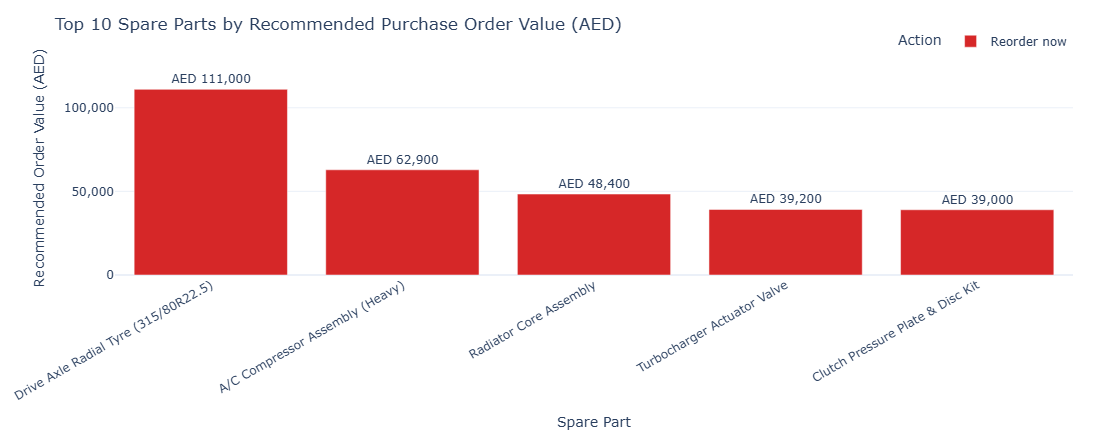

In [7]:
# 1. Filter & display Urgent Purchase Requisition (PR) escalations
urgent_prs = plan_df[plan_df["urgent_pr_escalation"]].copy()
pr_cols = [
    "part_number",
    "part_name",
    "hub_location",
    "supplier",
    "criticality",
    "net_available_stock",
    "reorder_point_qty",
    "recommended_order_qty",
    "recommended_order_value_aed",
    "delayed_wo_count",
    "total_wo_downtime_hrs",
    "stockout_risk_score",
]

total_urgent_val = urgent_prs["recommended_order_value_aed"].sum()
total_delayed_wos = int(plan_df["delayed_wo_count"].sum())
total_downtime_hrs = plan_df["total_wo_downtime_hrs"].sum()

print(
    f"Urgent PR Escalations: {len(urgent_prs)} parts | "
    f"Urgent PO Value: AED {total_urgent_val:,.2f} | "
    f"Delayed WOs: {total_delayed_wos} | "
    f"Downtime: {total_downtime_hrs:,.1f} hrs"
)
display(urgent_prs[pr_cols])

# 2. Summary of parts with active delayed vehicle work orders
delayed_parts = plan_df[plan_df["delayed_wo_count"] > 0].sort_values(
    ["total_wo_downtime_hrs", "delayed_wo_count"], ascending=[False, False]
)
print("\n== Spare Parts Driving Delayed Vehicle Work Orders ==")
display(
    delayed_parts[
        [
            "part_number",
            "part_name",
            "vehicle_type",
            "hub_location",
            "usable_on_hand_qty",
            "safety_stock_qty",
            "delayed_wo_count",
            "total_wo_delay_days",
            "total_wo_downtime_hrs",
            "recommended_action",
        ]
    ]
)

# 3. Top 5 Spare Parts by Recommended Purchase Order Value (AED)
top_orders = (
    plan_df[plan_df["recommended_order_value_aed"] > 0]
    .sort_values("recommended_order_value_aed", ascending=False)
    .head(5)
    .copy()
)
top_orders["order_val_label"] = top_orders["recommended_order_value_aed"].map(
    lambda x: f"AED {x:,.0f}"
)

fig = px.bar(
    top_orders,
    x="part_name",
    y="recommended_order_value_aed",
    color="recommended_action",
    text="order_val_label",
    hover_data={
        "part_number": True,
        "hub_location": True,
        "recommended_order_qty": True,
        "urgent_pr_escalation": True,
        "recommended_order_value_aed": ":,.2f",
    },
    color_discrete_map={
        "Reorder now": "#d62728",
        "Monitor closely": "#ff7f0e",
        "Excess stock": "#1f77b4",
        "Healthy": "#2ca02c",
        "Review master data": "#7f7f7f",
    },
    title="Top 10 Spare Parts by Recommended Purchase Order Value (AED)",
    labels={
        "recommended_order_value_aed": "Recommended Order Value (AED)",
        "part_name": "Spare Part",
        "recommended_action": "Action",
    },
)

fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(
    height=440,
    template="plotly_white",
    xaxis_tickangle=-30,
    yaxis_tickformat=",.0f",
    margin=dict(l=20, r=20, t=60, b=90),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
)
fig.show()

#### **Export Master Optimisation & Reorder Plan CSVs**

In [8]:
master_path = proc_dir / "inventory_optimisation_master.csv"
reorder_path = proc_dir / "procurement_reorder_plan.csv"

plan_df.to_csv(master_path, index=False)

reorder_export = plan_df[plan_df["recommended_order_qty"] > 0][
    [
        "snapshot_date",
        "part_number",
        "part_name",
        "category",
        "vehicle_type",
        "hub_location",
        "supplier",
        "criticality",
        "abc_xyz_segment",
        "on_hand_qty",
        "due_in_qty",
        "reserved_qty",
        "unserviceable_qty",
        "net_available_stock",
        "safety_stock_qty",
        "reorder_point_qty",
        "target_stock_qty",
        "recommended_order_qty",
        "unit_cost_aed",
        "recommended_order_value_aed",
        "delayed_wo_count",
        "total_wo_downtime_hrs",
        "urgent_pr_escalation",
        "stockout_risk_score",
        "recommended_action",
    ]
].sort_values(["urgent_pr_escalation", "recommended_order_value_aed"], ascending=[False, False])

reorder_export.to_csv(reorder_path, index=False)

print(f"Saved master file: {master_path} ({len(plan_df)} rows)")
print(f"Saved reorder plan: {reorder_path} ({len(reorder_export)} rows)")

Saved master file: C:\Users\tohiba\Desktop\fleet-spare-parts-inventory-optimiser\data\processed\inventory_optimisation_master.csv (28 rows)
Saved reorder plan: C:\Users\tohiba\Desktop\fleet-spare-parts-inventory-optimiser\data\processed\procurement_reorder_plan.csv (16 rows)
